In [1]:
# Installed required libraries for LPC Speech Processing
!pip install librosa soundfile numpy scipy matplotlib pandas

In [2]:
# Cell 2: Imports and Configuration
import numpy as np
import pandas as pd
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt

from scipy import signal
from IPython.display import Audio, display

# Standard Speech Processing Parameters
TARGET_SR = 16000          # Processing sample rate (16 kHz)
FRAME_DURATION = 0.025     # Frame length (25 ms)
HOP_DURATION = 0.010       # Hop shift (10 ms)
PREEMPH_COEF = 0.95        # Pre-emphasis factor (alpha)
LPC_ORDER = 16             # LPC Order (p = 16)

# Frame and Hop lengths in samples
FRAME_LENGTH = int(TARGET_SR * FRAME_DURATION)  # 400 samples
HOP_LENGTH = int(TARGET_SR * HOP_DURATION)      # 160 samples

print(f"Target Sampling Rate: {TARGET_SR} Hz")
print(f"Frame Length: {FRAME_LENGTH} samples ({FRAME_DURATION * 1000:.1f} ms)")
print(f"Hop Length: {HOP_LENGTH} samples ({HOP_DURATION * 1000:.1f} ms)")
print(f"LPC Order (p): {LPC_ORDER}")

Target Sampling Rate: 16000 Hz
Frame Length: 400 samples (25.0 ms)
Hop Length: 160 samples (10.0 ms)
LPC Order (p): 16


--- Audio Recording Metadata ---
Original Sampling Rate (Fs): 48000 Hz
Total Duration: 2.23 seconds
Total Samples: 107136
Channels: Mono


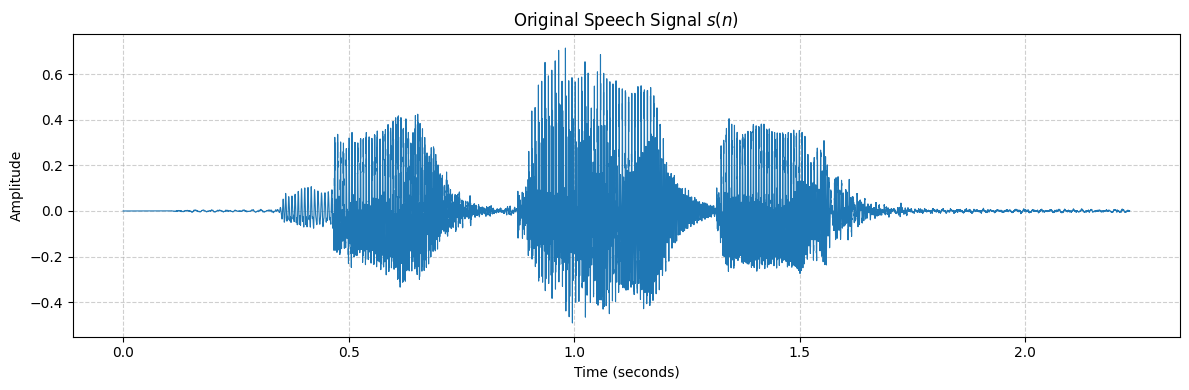

In [3]:
# Cell 3: Load original audio and inspect properties
from pathlib import Path

audio_candidates = [
    Path("../audio/original/Rahul_voice_recording_BIT.wav"),
    Path("audio/original/Rahul_voice_recording_BIT.wav"),
    Path("/content/Rahul_voice_recording_BIT.wav")
]

audio_path = next(
    (str(p) for p in audio_candidates if p.exists()),
    None
)

if audio_path is None:
    raise FileNotFoundError(
        "Original audio file not found. Please place it in audio/original/"
    )

# sr=None maintain karta hai original sampling rate ko
y_raw, orig_sr = librosa.load(audio_path, sr=None, mono=True)
total_duration = len(y_raw) / orig_sr

print("--- Audio Recording Metadata ---")
print(f"Original Sampling Rate (Fs): {orig_sr} Hz")
print(f"Total Duration: {total_duration:.2f} seconds")
print(f"Total Samples: {len(y_raw)}")
print(f"Channels: Mono")

# Colab playback player
display(Audio(y_raw, rate=orig_sr))

# Time-domain waveform s(n) plot
plt.figure(figsize=(12, 4))
time_axis = np.linspace(0, total_duration, len(y_raw))
plt.plot(time_axis, y_raw, color='#1f77b4', linewidth=0.8)
plt.title("Original Speech Signal $s(n)$", fontsize=12)
plt.xlabel("Time (seconds)", fontsize=10)
plt.ylabel("Amplitude", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

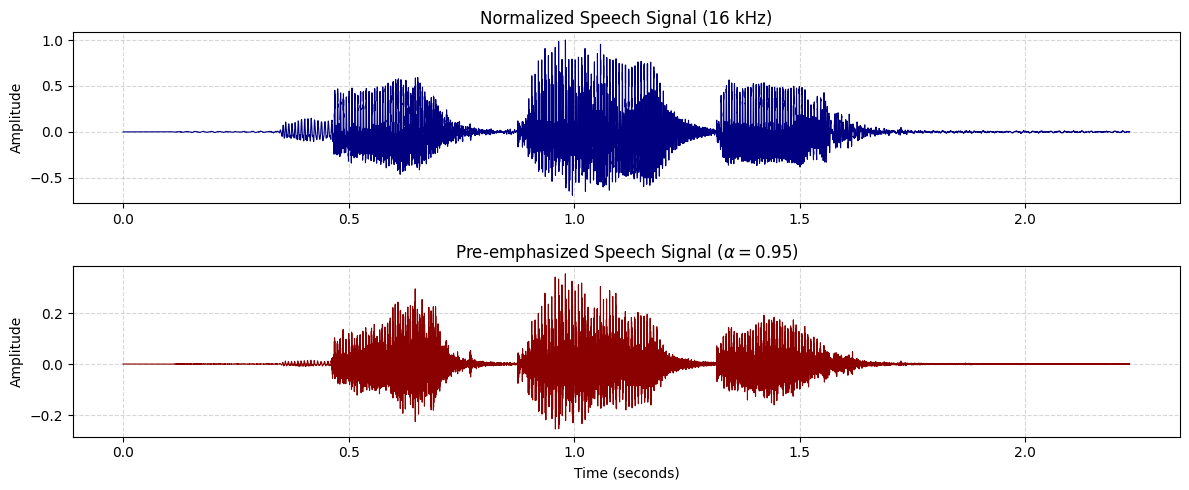

In [5]:
# Cell 4: Resampling, Normalization, and Pre-emphasis
if orig_sr != TARGET_SR:
    y_16k = librosa.resample(y_raw, orig_sr=orig_sr, target_sr=TARGET_SR)
else:
    y_16k = y_raw.copy()

# Peak Normalization [-1.0, 1.0]
max_amp = np.max(np.abs(y_16k))
y_norm = y_16k / max_amp if max_amp > 0 else y_16k

# Pre-emphasis Filter (alpha = 0.95)
y_pre = librosa.effects.preemphasis(y_norm, coef=PREEMPH_COEF)

# Save preprocessed file
sf.write("preprocessed_voice.wav", y_pre, TARGET_SR)

# Comparison Plot
plt.figure(figsize=(12, 5))
time_proc = np.linspace(0, len(y_norm) / TARGET_SR, len(y_norm))

plt.subplot(2, 1, 1)
plt.plot(time_proc, y_norm, color='navy', linewidth=0.8)
plt.title("Normalized Speech Signal (16 kHz)")
plt.ylabel("Amplitude")
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(2, 1, 2)
plt.plot(time_proc, y_pre, color='darkred', linewidth=0.8)
plt.title(fr"Pre-emphasized Speech Signal ($\alpha = {PREEMPH_COEF}$)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

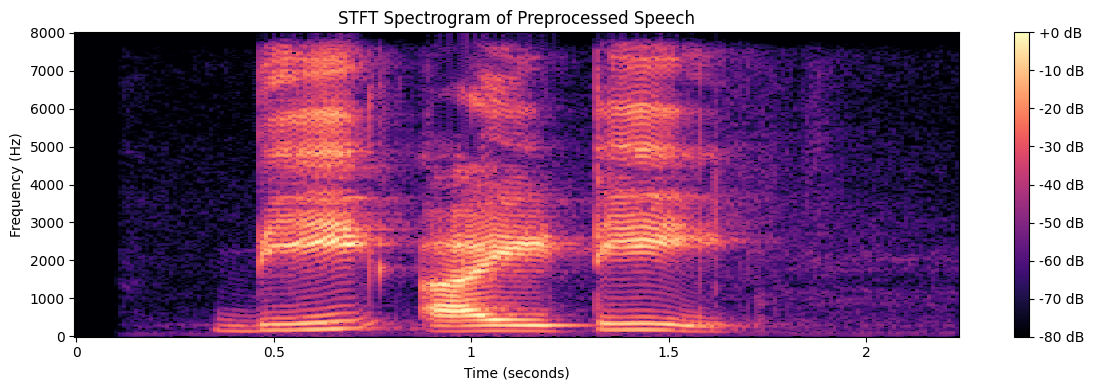

In [6]:
# Cell 5: STFT Spectrogram
D = librosa.stft(y_pre, n_fft=512, hop_length=HOP_LENGTH, win_length=FRAME_LENGTH, window='hamming')
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(S_db, sr=TARGET_SR, hop_length=HOP_LENGTH, x_axis='time', y_axis='linear', cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.title("STFT Spectrogram of Preprocessed Speech")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.tight_layout()
plt.show()

In [7]:
# Cell 6: Levinson-Durbin Recursion & Burg LPC
def levinson_durbin(r, order):
    a = np.zeros(order + 1)
    a[0] = 1.0
    e = r[0]
    if e == 0:
        return a, 0.0

    for i in range(1, order + 1):
        acc = sum(a[j] * r[i - j] for j in range(1, i))
        k = (r[i] - acc) / e
        a_prev = a.copy()
        a[i] = k
        for j in range(1, i):
            a[j] = a_prev[j] - k * a_prev[i - j]
        e *= (1.0 - k**2)

    a_poly = np.zeros(order + 1)
    a_poly[0] = 1.0
    a_poly[1:] = -a[1:]
    return a_poly, e

# Single voiced frame analysis
sample_start = len(y_pre) // 2
sample_end = sample_start + FRAME_LENGTH
test_frame = y_pre[sample_start:sample_end] * signal.windows.hamming(FRAME_LENGTH)

# Method 1: Autocorrelation + Levinson-Durbin
r_autocorr = signal.correlate(test_frame, test_frame, mode='full')
r_half = r_autocorr[len(test_frame) - 1 : len(test_frame) + LPC_ORDER]
a_levinson, _ = levinson_durbin(r_half, LPC_ORDER)

# Method 2: Librosa Burg Method
a_burg = librosa.lpc(test_frame, order=LPC_ORDER)

df_coeffs = pd.DataFrame({
    'Coeff': [f'a[{i}]' for i in range(LPC_ORDER + 1)],
    'Levinson-Durbin': a_levinson,
    'Librosa (Burg)': a_burg,
    'Abs Diff': np.abs(a_levinson - a_burg)
})
print("--- LPC Coefficient Comparison ---")
print(df_coeffs.to_string(index=False))

--- LPC Coefficient Comparison ---
Coeff  Levinson-Durbin  Librosa (Burg)  Abs Diff
 a[0]         1.000000        1.000000  0.000000
 a[1]        -1.120976       -1.117997  0.002979
 a[2]         0.722465        0.720166  0.002300
 a[3]        -0.187844       -0.185929  0.001915
 a[4]         0.274120        0.274142  0.000022
 a[5]        -0.821093       -0.823560  0.002467
 a[6]         0.279452        0.278940  0.000512
 a[7]        -0.299049       -0.298987  0.000062
 a[8]        -0.027466       -0.029131  0.001665
 a[9]        -0.183332       -0.185796  0.002464
a[10]         0.520773        0.524490  0.003716
a[11]        -0.364014       -0.363108  0.000906
a[12]         0.505625        0.504918  0.000707
a[13]        -0.384719       -0.383810  0.000908
a[14]         0.554474        0.555931  0.001456
a[15]        -0.231285       -0.230801  0.000484
a[16]         0.008850        0.007304  0.001546


Residual Signal Audio Playback:


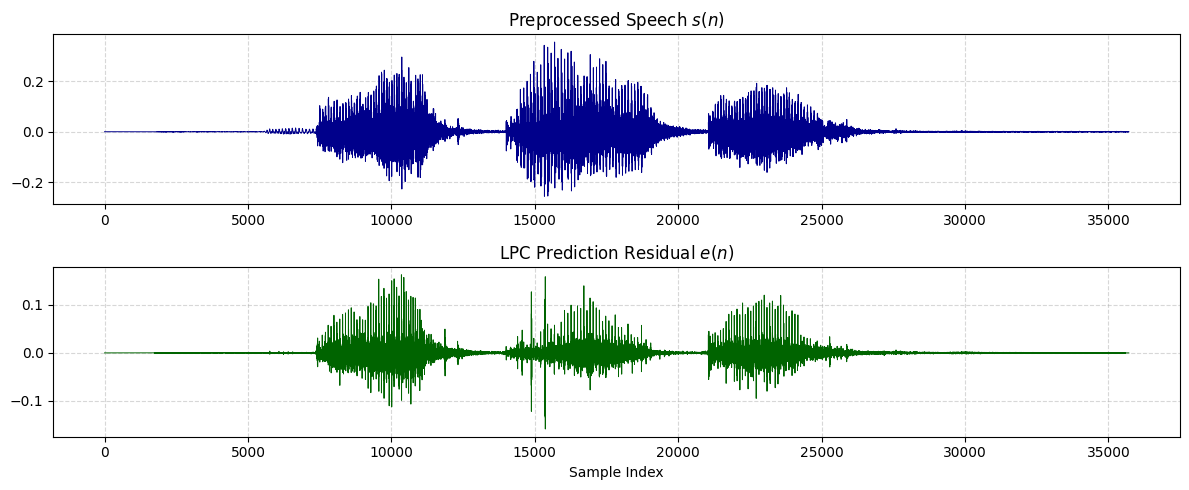

In [8]:
# Cell 7: Analysis Filtering E(z) = A(z) * S(z)
frames = librosa.util.frame(y_pre, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH).T
num_frames = frames.shape[0]
window = signal.windows.hamming(FRAME_LENGTH)

residual_frames = np.zeros_like(frames)
lpc_all_frames = np.zeros((num_frames, LPC_ORDER + 1))

for i in range(num_frames):
    frame_win = frames[i] * window
    a_poly = librosa.lpc(frame_win, order=LPC_ORDER)
    lpc_all_frames[i] = a_poly
    residual_frames[i] = signal.lfilter(a_poly, [1.0], frames[i])

# Overlap-add reconstruction of 1D residual
residual_signal = np.zeros(len(y_pre))
window_sum = np.zeros(len(y_pre))

for i in range(num_frames):
    start = i * HOP_LENGTH
    end = start + FRAME_LENGTH
    residual_signal[start:end] += residual_frames[i]
    window_sum[start:end] += 1.0

window_sum[window_sum == 0] = 1.0
residual_signal /= window_sum

sf.write("residual_signal.wav", residual_signal, TARGET_SR)
print("Residual Signal Audio Playback:")
display(Audio(residual_signal, rate=TARGET_SR))

# Plot Residual vs Speech
plt.figure(figsize=(12, 5))
plt.subplot(2, 1, 1)
plt.plot(y_pre, color='darkblue', linewidth=0.7)
plt.title("Preprocessed Speech $s(n)$")
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(2, 1, 2)
plt.plot(residual_signal, color='darkgreen', linewidth=0.7)
plt.title("LPC Prediction Residual $e(n)$")
plt.xlabel("Sample Index")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [9]:
# Cell 8: Synthesis Filtering S_hat(z) = E(z) / A(z)
reconstructed_frames = np.zeros_like(frames)
for i in range(num_frames):
    a_poly = lpc_all_frames[i]
    reconstructed_frames[i] = signal.lfilter([1.0], a_poly, residual_frames[i])

reconstructed_signal = np.zeros(len(y_pre))
for i in range(num_frames):
    start = i * HOP_LENGTH
    end = start + FRAME_LENGTH
    reconstructed_signal[start:end] += reconstructed_frames[i]

reconstructed_signal /= window_sum
reconstructed_speech = librosa.effects.deemphasis(reconstructed_signal, coef=PREEMPH_COEF)

sf.write("reconstructed_voice.wav", reconstructed_speech, TARGET_SR)
print("Reconstructed Speech Audio Playback:")
display(Audio(reconstructed_speech, rate=TARGET_SR))

Reconstructed Speech Audio Playback:


<>:23: SyntaxWarning: invalid escape sequence '\h'
<>:30: SyntaxWarning: invalid escape sequence '\h'
<>:23: SyntaxWarning: invalid escape sequence '\h'
<>:30: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_1462/386026286.py:23: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(s_rec, label='Reconstructed $\hat{s}(n)$', color='orange', alpha=0.7, linewidth=0.8)
/tmp/ipykernel_1462/386026286.py:30: SyntaxWarning: invalid escape sequence '\h'
  plt.title("Reconstruction Error $s(n) - \hat{s}(n)$")


--- LPC Synthesis Metrics ---
              Metric    Value
                RMSE 0.000113
            SNR (dB) 62.87 dB
     Correlation (r)   1.0000
Prediction Gain (dB) 22.88 dB


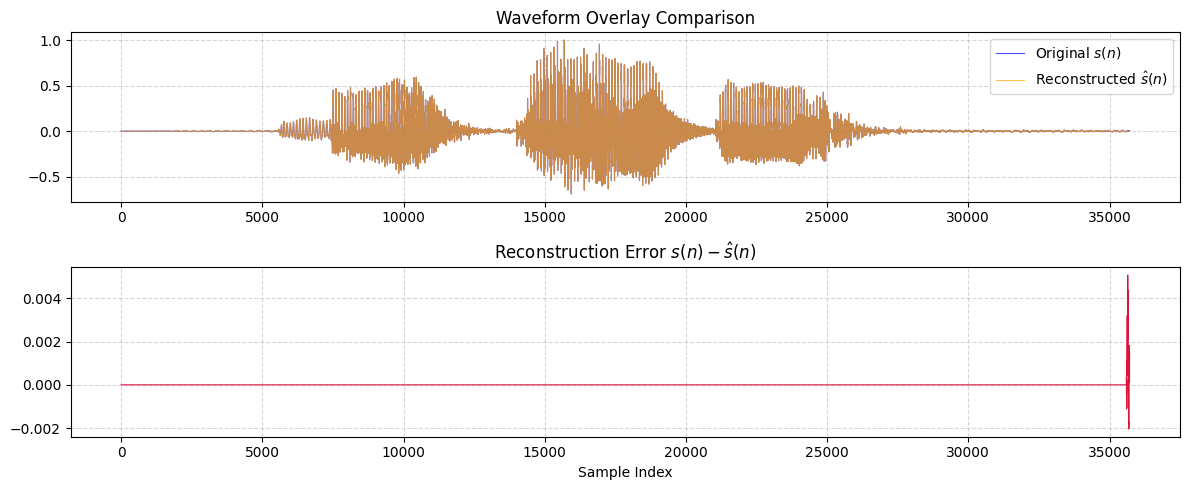

In [10]:
# Cell 9: Performance Metrics
min_len = min(len(y_norm), len(reconstructed_speech))
s_orig = y_norm[:min_len]
s_rec = reconstructed_speech[:min_len]
e_sig = residual_signal[:min_len]

rmse = np.sqrt(np.mean((s_orig - s_rec) ** 2))
snr_db = 10 * np.log10(np.mean(s_orig ** 2) / np.mean((s_orig - s_rec) ** 2))
corr_coeff = np.corrcoef(s_orig, s_rec)[0, 1]
pred_gain_db = 10 * np.log10(np.sum(s_orig ** 2) / np.sum(e_sig ** 2))

metrics_df = pd.DataFrame({
    'Metric': ['RMSE', 'SNR (dB)', 'Correlation (r)', 'Prediction Gain (dB)'],
    'Value': [f"{rmse:.6f}", f"{snr_db:.2f} dB", f"{corr_coeff:.4f}", f"{pred_gain_db:.2f} dB"]
})
print("--- LPC Synthesis Metrics ---")
print(metrics_df.to_string(index=False))

# Overlay Plot
plt.figure(figsize=(12, 5))
plt.subplot(2, 1, 1)
plt.plot(s_orig, label='Original $s(n)$', color='blue', alpha=0.7, linewidth=0.8)
plt.plot(s_rec, label='Reconstructed $\hat{s}(n)$', color='orange', alpha=0.7, linewidth=0.8)
plt.title("Waveform Overlay Comparison")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(2, 1, 2)
plt.plot(s_orig - s_rec, color='crimson', linewidth=0.8)
plt.title("Reconstruction Error $s(n) - \hat{s}(n)$")
plt.xlabel("Sample Index")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Formants for Voiced Frame #95:
F1 = 711.0 Hz, F2 = 1429.6 Hz, F3 = 2388.2 Hz


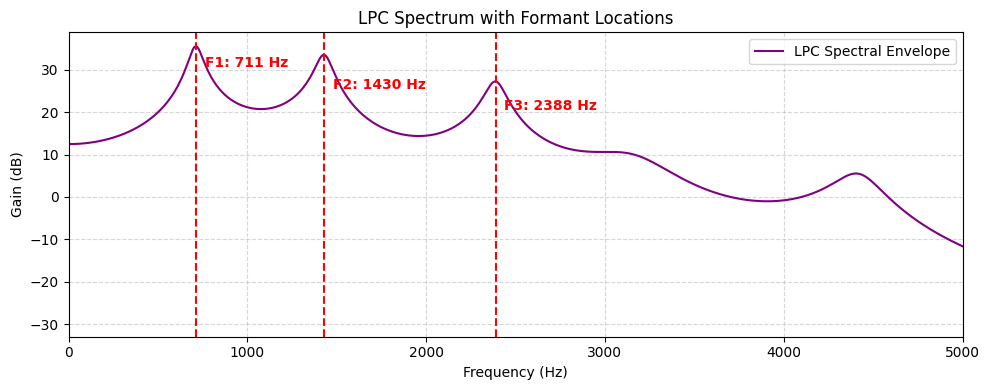

In [11]:
# Cell 10: Formant Estimation
voiced_idx = np.argmax(np.sum(frames**2, axis=1))
a_voiced = lpc_all_frames[voiced_idx]
roots = np.roots(a_voiced)

formants = []
for r in roots:
    if np.imag(r) > 0:
        freq = np.angle(r) * (TARGET_SR / (2 * np.pi))
        bw = - (TARGET_SR / np.pi) * np.log(np.abs(r))
        if 50 < freq < (TARGET_SR / 2) and bw < 400:
            formants.append(freq)

formants = sorted(formants)
f1, f2, f3 = formants[0], formants[1], formants[2]

print(f"Formants for Voiced Frame #{voiced_idx}:")
print(f"F1 = {f1:.1f} Hz, F2 = {f2:.1f} Hz, F3 = {f3:.1f} Hz")

w, h = signal.freqz([1.0], a_voiced, worN=1024, fs=TARGET_SR)
lpc_db = 20 * np.log10(np.abs(h))

plt.figure(figsize=(10, 4))
plt.plot(w, lpc_db, color='purple', linewidth=1.5, label='LPC Spectral Envelope')
for idx, f_val in enumerate([f1, f2, f3], start=1):
    plt.axvline(f_val, color='red', linestyle='--')
    plt.text(f_val + 50, np.max(lpc_db) - (idx * 5), f'F{idx}: {f_val:.0f} Hz', color='red', fontweight='bold')
plt.title("LPC Spectrum with Formant Locations")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Gain (dB)")
plt.xlim(0, 5000)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

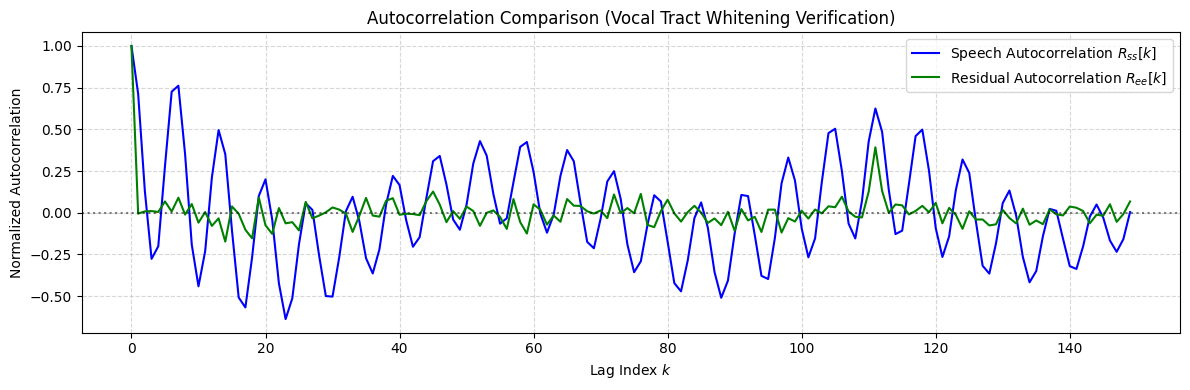

In [12]:
# Cell 11: Residual Autocorrelation
def get_autocorr(sig, max_lags=150):
    ac = signal.correlate(sig, sig, mode='full')
    mid = len(ac) // 2
    return ac[mid : mid + max_lags] / ac[mid]

lags = np.arange(150)
r_speech = get_autocorr(y_pre[sample_start:sample_end])
r_res = get_autocorr(residual_signal[sample_start:sample_end])

plt.figure(figsize=(12, 4))
plt.plot(lags, r_speech, label='Speech Autocorrelation $R_{ss}[k]$', color='blue')
plt.plot(lags, r_res, label='Residual Autocorrelation $R_{ee}[k]$', color='green')
plt.title("Autocorrelation Comparison (Vocal Tract Whitening Verification)")
plt.xlabel("Lag Index $k$")
plt.ylabel("Normalized Autocorrelation")
plt.axhline(0, color='black', linestyle=':', alpha=0.5)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()